(4900, 3)
Simulation took 39.37737035751343 seconds
{'grid_building_time': 0.007756191, 'num_collisions': 2236529, 'num_crossings': 997763471, 'total_time': 39.323039191999996, 'trace_time': 39.315283001}


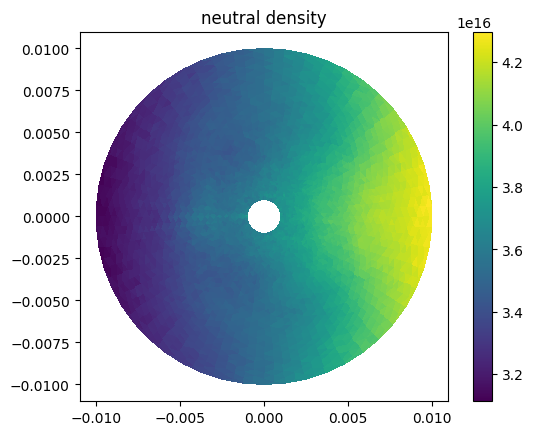

In [1]:
import matplotlib.pyplot as plt
import matplotlib.tri as tri
import numpy as np
import math
import json
import time
import subprocess

# First create the x and y coordinates of the points.
n_angles = 50

n_radii = 50
min_radius = 0.001
radii = np.linspace(min_radius, 0.01, n_radii)

angles = np.linspace(0, 2 * np.pi, n_angles, endpoint=False)
angles = np.repeat(angles[..., np.newaxis], n_radii, axis=1)
angles[:, 1::2] += np.pi / n_angles

x = (radii * np.cos(angles)).flatten()
y = (radii * np.sin(angles)).flatten()
z = (np.cos(radii) * np.cos(3 * angles)).flatten()

# x = np.array([0., 2., 0.])
# y = np.array([0., 0., 2.])

# Create the Triangulation; no triangles so Delaunay triangulation created.
triang = tri.Triangulation(x, y)

# Mask off unwanted triangles.
triang.set_mask(np.hypot(x[triang.triangles].mean(axis=1),
                         y[triang.triangles].mean(axis=1))
                < min_radius)

triangles = triang.get_masked_triangles()
ncells = triangles.shape[0]
xy = np.concatenate((x[:, None], y[:, None]), axis=1)

print(triangles.shape)


config = {}

plasma_dens = np.zeros(ncells, dtype=np.float64)
plasma_temp = np.zeros(ncells, dtype=np.float64)
plasma_vel_x = np.zeros(ncells, dtype=np.float64)
plasma_vel_y = np.zeros(ncells, dtype=np.float64)
plasma_vel_z = np.zeros(ncells, dtype=np.float64)

for i in range(ncells):
    plasma_dens[i] = 1.0e19

for i in range(ncells):
    plasma_temp[i] = 1.0

for i in range(ncells):
    plasma_vel_x[i] = 1.0e4

for i in range(ncells):
    plasma_vel_y[i] = 0

config["background"] = {
    "plasma_dens": plasma_dens.tolist(),
    "plasma_temp": plasma_temp.tolist(),
    "plasma_vel_x": plasma_vel_x.tolist(),
    "plasma_vel_y": plasma_vel_y.tolist(),
    "plasma_vel_z": plasma_vel_z.tolist()
}

config["mesh"] = {
    "type": "triangle",
    "vertices": xy.tolist(),
    "triangles": triangles.tolist()
}


config["sources"] = [
    {
        "type": "point",
        "pos": [-0.006, 0, 0],
        "vel_mean": [1.0e4, 0, 0],
        "vel_stddev": 100,
        "n_particles": 1000,
        "intensity": 1.0e15
    }
]

config["boundary_conditions"] = [
    "reflective"
]

config["max_steps"] = 1000000
config["seed"] = 0

inputstring = json.dumps(config)

# write inputstring to file
with open("input.json", "w") as f:
    f.write(inputstring)

start_time = time.time()
subprocess.check_output(["eigrene-json"]).decode("utf-8")
end_time = time.time()

print("Simulation took", end_time - start_time, "seconds")

with open("output.json", "r") as f:
    outputstring = f.read()

output = json.loads(outputstring)

stats = output["stats"]
print(stats)

neutral_density = np.array(output["density"])

fig1, ax1 = plt.subplots()
ax1.set_aspect('equal')
tpc = ax1.tripcolor(x, y, neutral_density, triangles=triangles, shading='flat')
fig1.colorbar(tpc)
ax1.set_title('neutral density')

plt.show()